# Session 3, the CLT at work: audit sampling in financial services

> **An auditor cannot test all 10,000 transactions in a ledger. They test a sample.**
> **Why can a sample of 50 stand for the whole ledger? The Central Limit Theorem.**

This is the CLT doing its headline job in your own field. The ledger is skewed, nothing like a bell. Yet the average of a sample drawn from it is tightly predictable, and that is the whole licence for audit sampling.

We build it in four steps: see the ledger is not normal, watch one sample wobble, watch the averages form a bell, then turn one sample into a defensible range.

## Step 1, the ledger is not a bell

Real transaction amounts pile up at the low end with a long tail of large ones. The mean sits above the median, the signature of right skew. The Q-Q plot confirms it: the points curl off the line.

ledger size:   10,000 transactions
mean amount:   EUR 2,717
median amount: EUR 1,977   (mean above median = right skew)


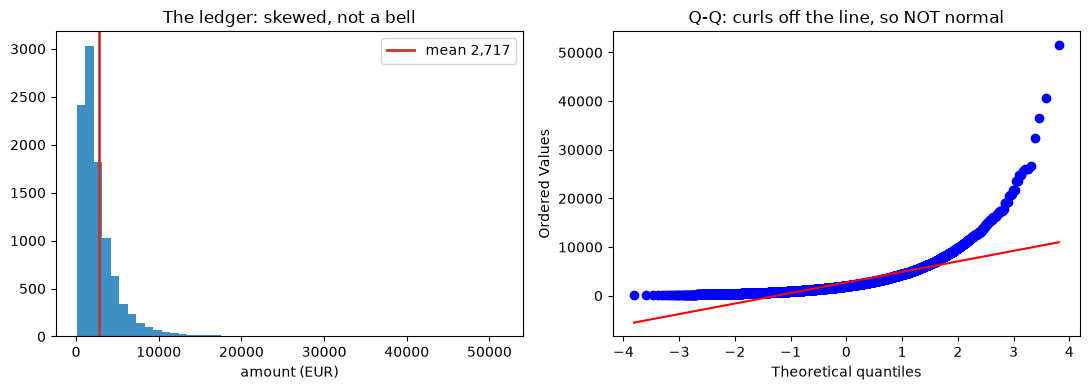

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(7)
# A ledger of 10,000 transaction amounts (EUR), right-skewed like real invoice/claim data.
ledger = rng.lognormal(mean=7.6, sigma=0.8, size=10_000)

print(f"ledger size:   {ledger.size:,} transactions")
print(f"mean amount:   EUR {ledger.mean():,.0f}")
print(f"median amount: EUR {np.median(ledger):,.0f}   (mean above median = right skew)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ledger, bins=50, color='#0D73B8', alpha=0.8)
ax[0].axvline(ledger.mean(), color='#C0392B', lw=2, label=f'mean {ledger.mean():,.0f}')
ax[0].set_title('The ledger: skewed, not a bell'); ax[0].set_xlabel('amount (EUR)')
ax[0].legend()
stats.probplot(ledger, dist='norm', plot=ax[1])
ax[1].set_title('Q-Q: curls off the line, so NOT normal')
plt.tight_layout(); plt.show()

## Step 2, one sample wobbles

The auditor draws a sample of 50 transactions and averages them. That average estimates the true mean. Draw another sample and the average lands somewhere slightly different. The sample mean is itself a moving target.

In [2]:
n = 50
for i in range(5):
    sample = rng.choice(ledger, size=n, replace=False)
    print(f"sample {i + 1}: mean of 50 = EUR {sample.mean():,.0f}")
print(f"\ntrue ledger mean = EUR {ledger.mean():,.0f}")

sample 1: mean of 50 = EUR 2,709
sample 2: mean of 50 = EUR 2,993
sample 3: mean of 50 = EUR 3,015
sample 4: mean of 50 = EUR 2,424
sample 5: mean of 50 = EUR 2,717

true ledger mean = EUR 2,717


## Step 3, the CLT: the sample mean's distribution is a bell

Now draw the sample of 50 many times over and collect every average. Those averages are the **sampling distribution of the mean**. The ledger is skewed, but the averages pile up into a tight bell, centred on the true mean. That is the Central Limit Theorem, on real financial data.

average of the 5,000 sample means: EUR 2,717  (vs true mean EUR 2,717)
spread of the sample means (their SD): EUR 365


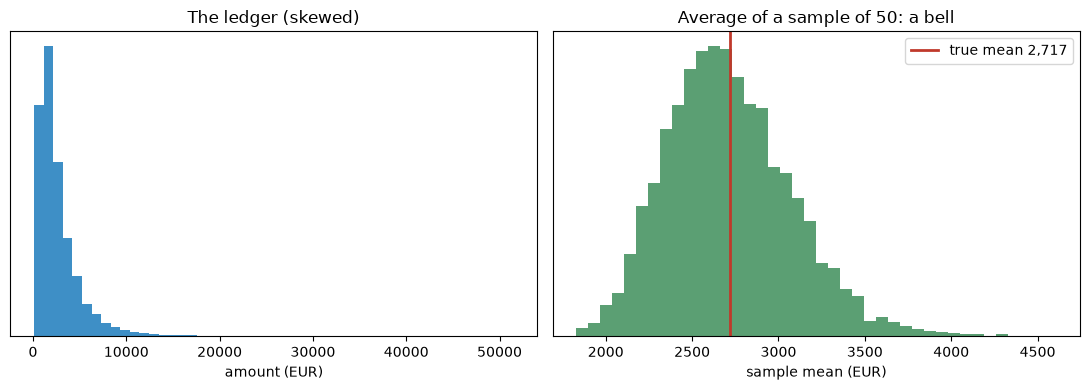

In [3]:
sample_means = rng.choice(ledger, size=(5_000, n), replace=True).mean(axis=1)

print(f"average of the 5,000 sample means: EUR {sample_means.mean():,.0f}  (vs true mean EUR {ledger.mean():,.0f})")
print(f"spread of the sample means (their SD): EUR {sample_means.std(ddof=1):,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(ledger, bins=50, color='#0D73B8', alpha=0.8)
ax[0].set_title('The ledger (skewed)'); ax[0].set_xlabel('amount (EUR)'); ax[0].set_yticks([])
ax[1].hist(sample_means, bins=40, color='#3E8E5A', alpha=0.85)
ax[1].axvline(ledger.mean(), color='#C0392B', lw=2, label=f'true mean {ledger.mean():,.0f}')
ax[1].set_title('Average of a sample of 50: a bell')
ax[1].set_xlabel('sample mean (EUR)'); ax[1].set_yticks([]); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 4, standard error and the audit payoff

The spread of that bell has a name and a formula: the **standard error**, `SE = sd / sqrt(n)`. It shrinks as the sample grows, with diminishing returns.

From one sample of 50, `mean +/- 2 * SE` is a range you can stand over. Next week this becomes a formal confidence interval. For the audit, it is the test: a recorded ledger total that implies an average far outside this range is a potential material misstatement, worth a closer look.

one sample of 50: mean EUR 2,713,  SE EUR 323
range we can stand over (mean +/- 2 SE): EUR 2,067 to EUR 3,359

recorded average EUR 2,717: inside, consistent with the sample
recorded average EUR 3,759: OUTSIDE, flag for review


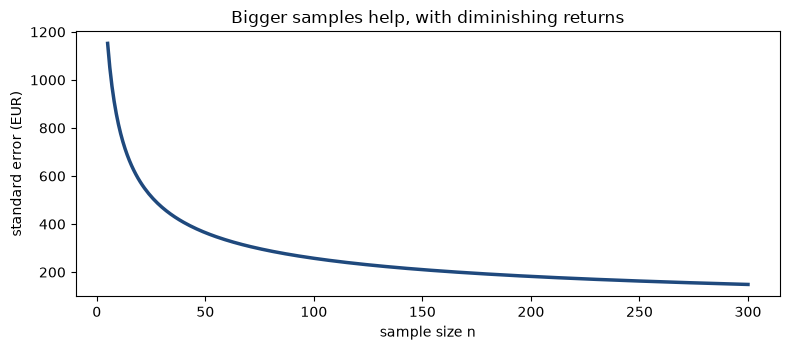

In [4]:
sample = rng.choice(ledger, size=n, replace=False)
se = sample.std(ddof=1) / np.sqrt(n)
lo, hi = sample.mean() - 2 * se, sample.mean() + 2 * se

print(f"one sample of {n}: mean EUR {sample.mean():,.0f},  SE EUR {se:,.0f}")
print(f"range we can stand over (mean +/- 2 SE): EUR {lo:,.0f} to EUR {hi:,.0f}")
print()
for recorded in (ledger.mean(), hi + 400):
    verdict = 'inside, consistent with the sample' if lo <= recorded <= hi else 'OUTSIDE, flag for review'
    print(f"recorded average EUR {recorded:,.0f}: {verdict}")

# How the standard error shrinks with sample size (diminishing returns).
ns = np.arange(5, 301)
plt.figure(figsize=(8, 3.6))
plt.plot(ns, ledger.std(ddof=1) / np.sqrt(ns), color='#1F497D', lw=2.5)
plt.xlabel('sample size n'); plt.ylabel('standard error (EUR)')
plt.title('Bigger samples help, with diminishing returns'); plt.tight_layout(); plt.show()

## Your call

Jot down, and push Claude on:
1. In two sentences a partner would accept, why can a sample of 50 speak for a ledger of 10,000?
2. The ledger was skewed, yet the sampling distribution was a bell. Which shape does the CLT describe, and which does it not?
3. The auditor wants the range half as wide. Roughly how much bigger must the sample be, and why is that expensive?
4. Where does this show up in the Deloitte audit-analytics capstone?